#### The dataset used in the assigned paper "Prediction of Thyroid Disease Using Machine Learning Algorithms" (ICACITE 2023) comes from the laboratory of a hospital in Iraq, comprising 2690 records, and is not publicly available. This project uses the publicly available UCI Thyroid Disease repository (thyroid0387.data, 9172 records) as an alternative, and constructs a three-class dataset (hyperthyroid / hypothyroid / normal) based on UCI official documentation's diagnostic code mappings. After excluding records not belonging to these three classes, a Naive Bayes classifier is trained. Although this dataset is not identical to the one used in the paper, both originate from the same thyroid disease classification task, and the methodology is comparable.

In [12]:
import pandas as pd
import numpy as np
import zipfile
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import CategoricalNB
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.utils import resample
import joblib

zip_path = "thyroid+disease.zip"
if not os.path.exists(zip_path):
    raise FileNotFoundError("Place thyroid+disease.zip in the same folder as the notebook")

with zipfile.ZipFile(zip_path, "r") as z:
    df = pd.read_csv(z.open("thyroid0387.data"), header=None,
                     skipinitialspace=True, dtype=str)

print("Shape:", df.shape)

Shape: (9172, 30)


In [13]:
columns = [
    "age","sex","on_thyroxine","query_on_thyroxine",
    "on_antithyroid_medication","sick","pregnant",
    "thyroid_surgery","I131_treatment","query_hypothyroid",
    "query_hyperthyroid","lithium","goitre","tumor",
    "hypopituitary","psych","TSH_measured","TSH",
    "T3_measured","T3","TT4_measured","TT4",
    "T4U_measured","T4U","FTI_measured","FTI",
    "TBG_measured","TBG","referral_source","diagnosis_raw"
]
df.columns = columns

df["diagnosis"] = df["diagnosis_raw"].str.extract(r"^([A-Z-]+(?:\|[A-Z-]+)?)")
print(df["diagnosis"].value_counts().head(10))

diagnosis
-    6771
K     436
G     359
I     346
F     233
R     196
A     147
L     115
M     111
N     110
Name: count, dtype: int64


In [14]:
diagnosis_mapping = {
    "A":"hyperthyroid","B":"hyperthyroid","C":"hyperthyroid","D":"hyperthyroid",
    "E":"hypothyroid","F":"hypothyroid","G":"hypothyroid","H":"hypothyroid",
    "K":"non_thyroidal_illness",
    "-":"normal"
}
df["target"] = df["diagnosis"].map(diagnosis_mapping)
df_model = df.dropna(subset=["target"]).copy()

print(df_model["target"].value_counts())
# Expected: normal 6771, hypothyroid 593, non_thyroidal_illness 436, hyperthyroid 182

target
normal                   6771
hypothyroid               593
non_thyroidal_illness     436
hyperthyroid              182
Name: count, dtype: int64


In [15]:
feature_cols = [
    "age","sex","on_thyroxine","query_on_thyroxine",
    "on_antithyroid_medication","sick","pregnant",
    "thyroid_surgery","I131_treatment","query_hypothyroid",
    "query_hyperthyroid","lithium","goitre","tumor",
    "hypopituitary","psych","TSH","T3","TT4","T4U","FTI"
]

cont_cols = ["age","TSH","T3","TT4","T4U","FTI"]
bool_cols = ["on_thyroxine","query_on_thyroxine","on_antithyroid_medication",
             "sick","pregnant","thyroid_surgery","I131_treatment",
             "query_hypothyroid","query_hyperthyroid","lithium","goitre",
             "tumor","hypopituitary","psych"]

X = df_model[feature_cols].copy()

# Boolean: t→1, f→0, ?→2  (no negatives)
for c in bool_cols:
    X[c] = X[c].map({"t":1,"f":0}).fillna(2).astype(int)

# sex: M→1, F→0, ?→2
X["sex"] = X["sex"].map({"M":1,"F":0}).fillna(2).astype(int)

# Continuous: ?→NaN, fill with median
for c in cont_cols:
    X[c] = pd.to_numeric(X[c].replace("?", np.nan), errors="coerce")
    X[c] = X[c].fillna(X[c].median())

# Quantile bins → integers 0..3
disc = KBinsDiscretizer(n_bins=4, encode="ordinal", strategy="quantile")
X[cont_cols] = disc.fit_transform(X[cont_cols]).astype(int)

X = X.astype(int)
y = df_model["target"]

assert (X.values >= 0).all(), "Negative values still present!"
print(X.shape, y.shape)
X.head()

(7982, 21) (7982,)


,age,sex,on_thyroxine,query_on_thyroxine,on_antithyroid_medication,sick,pregnant,thyroid_surgery,I131_treatment,query_hypothyroid,...,lithium,goitre,tumor,hypopituitary,psych,TSH,T3,TT4,T4U,FTI
0,0,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,2,2,2,2
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,2,2,3,2,2
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,2,2,2,2,2
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,2,2,2,2,2
5,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,2,2,2,2,2


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Oversample only the training set to equal class sizes
train_df = pd.concat([X_train, y_train], axis=1)
max_n = train_df["target"].value_counts().max()
balanced_parts = []
for cls, g in train_df.groupby("target"):
    balanced_parts.append(
        resample(g, replace=True, n_samples=max_n, random_state=42)
    )
train_bal = pd.concat(balanced_parts).sample(frac=1, random_state=42)

X_train_bal = train_bal.drop(columns="target")
y_train_bal = train_bal["target"]

model = CategoricalNB(alpha=1.0)
model.fit(X_train_bal, y_train_bal)

y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.6950532247964935

Classification Report:
                       precision    recall  f1-score   support

         hyperthyroid       0.20      0.97      0.34        36
          hypothyroid       0.42      0.81      0.55       119
non_thyroidal_illness       0.26      0.79      0.39        87
               normal       0.98      0.67      0.80      1355

             accuracy                           0.70      1597
            macro avg       0.46      0.81      0.52      1597
         weighted avg       0.88      0.70      0.75      1597



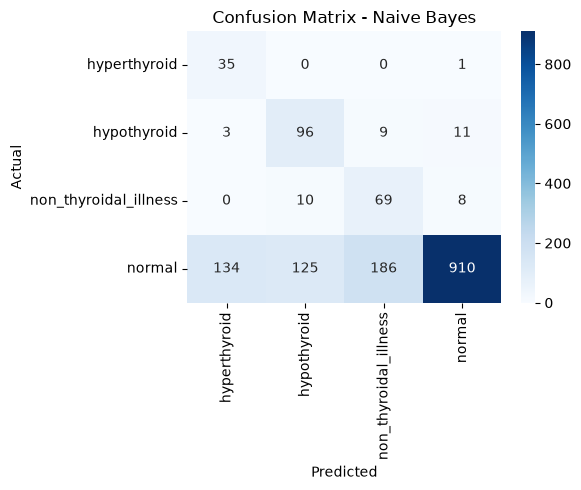

                       precision    recall  f1-score   support

         hyperthyroid       0.20      0.97      0.34        36
          hypothyroid       0.42      0.81      0.55       119
non_thyroidal_illness       0.26      0.79      0.39        87
               normal       0.98      0.67      0.80      1355

             accuracy                           0.70      1597
            macro avg       0.46      0.81      0.52      1597
         weighted avg       0.88      0.70      0.75      1597



In [17]:
os.makedirs("static/plots", exist_ok=True)

cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=model.classes_, yticklabels=model.classes_)
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title("Confusion Matrix - Naive Bayes")
plt.tight_layout()
plt.savefig("static/plots/confusion_matrix.png", dpi=120)
plt.show()

report = classification_report(y_test, y_pred, zero_division=0)
with open("static/plots/classification_report.txt","w") as f:
    f.write(report)
print(report)

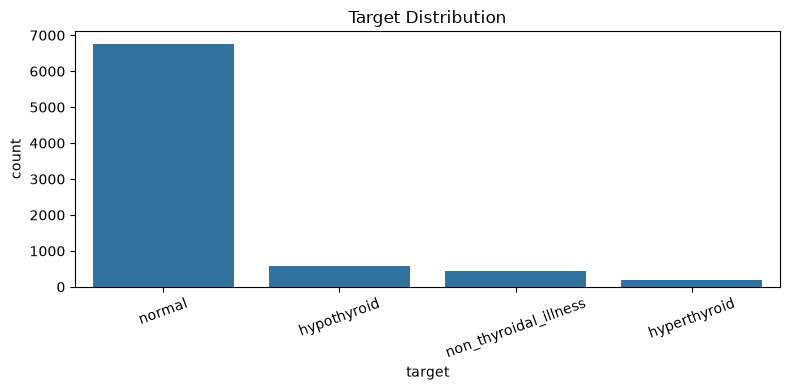

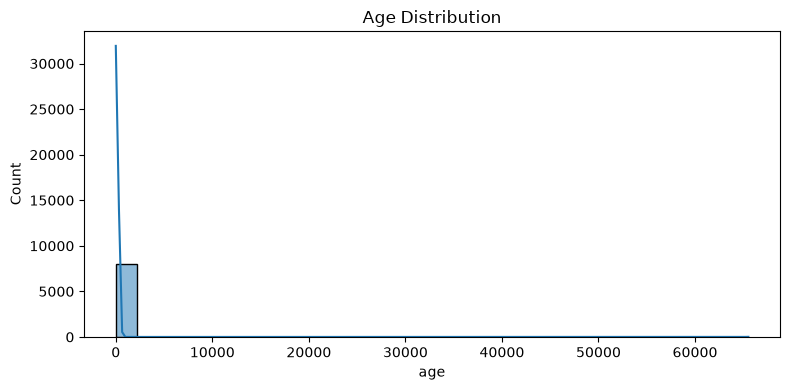

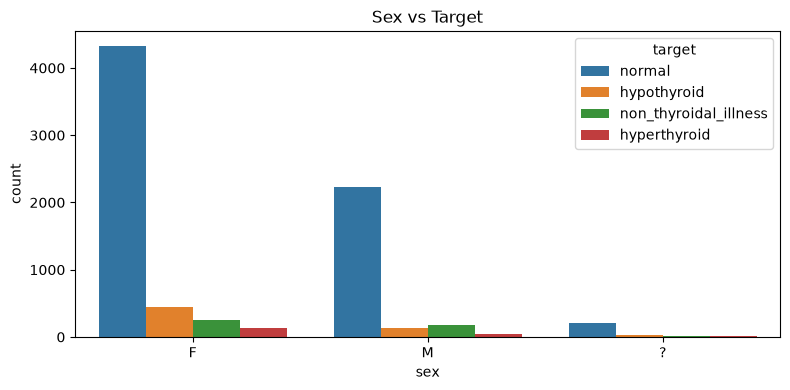

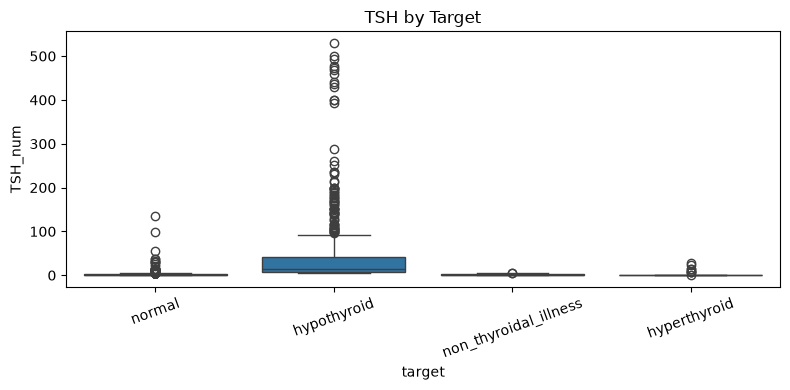

In [18]:
# 1. Target distribution
plt.figure(figsize=(8,4))
sns.countplot(data=df_model, x="target",
              order=df_model["target"].value_counts().index)
plt.title("Target Distribution"); plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("static/plots/target_dist.png", dpi=120)
plt.show()

# 2. Age distribution
plt.figure(figsize=(8,4))
sns.histplot(pd.to_numeric(df_model["age"], errors="coerce").dropna(),
             bins=30, kde=True)
plt.title("Age Distribution"); plt.tight_layout()
plt.savefig("static/plots/age_dist.png", dpi=120)
plt.show()

# 3. Sex vs Target
plt.figure(figsize=(8,4))
sns.countplot(data=df_model, x="sex", hue="target")
plt.title("Sex vs Target"); plt.tight_layout()
plt.savefig("static/plots/sex_target.png", dpi=120)
plt.show()

# 4. TSH by Target
df_model["TSH_num"] = pd.to_numeric(df_model["TSH"].replace("?", np.nan),
                                    errors="coerce")
plt.figure(figsize=(8,4))
sns.boxplot(data=df_model, x="target", y="TSH_num")
plt.title("TSH by Target"); plt.xticks(rotation=20); plt.tight_layout()
plt.savefig("static/plots/tsh_target.png", dpi=120)
plt.show()

In [19]:
joblib.dump(model, "model.pkl")
joblib.dump(disc, "discretizer.pkl")
joblib.dump(feature_cols, "feature_cols.pkl")
joblib.dump(bool_cols, "bool_cols.pkl")
joblib.dump(cont_cols, "cont_cols.pkl")
joblib.dump(list(model.classes_), "classes.pkl")
print("Saved: model.pkl, discretizer.pkl, feature_cols.pkl,",
      "bool_cols.pkl, cont_cols.pkl, classes.pkl")

Saved: model.pkl, discretizer.pkl, feature_cols.pkl, bool_cols.pkl, cont_cols.pkl, classes.pkl


In [20]:
def predict_one(input_dict):
    """input_dict: field → raw string value (e.g. {'age':'45','sex':'F', ...})"""
    row = pd.DataFrame([input_dict])[feature_cols]
    for c in bool_cols:
        row[c] = row[c].map({"t":1,"f":0}).fillna(2).astype(int)
    row["sex"] = row["sex"].map({"M":1,"F":0}).fillna(2).astype(int)
    for c in cont_cols:
        row[c] = pd.to_numeric(row[c].replace("?", np.nan), errors="coerce")
    for c in cont_cols:
        row[c] = row[c].fillna(0)  # simple fallback before binning
    row[cont_cols] = disc.transform(row[cont_cols]).astype(int)
    row = row.astype(int)
    proba = model.predict_proba(row)[0]
    idx = int(np.argmax(proba))
    return model.classes_[idx], float(proba[idx]) * 100

# Smoke test
print(predict_one({
    "age":"45","sex":"F","on_thyroxine":"f","query_on_thyroxine":"f",
    "on_antithyroid_medication":"f","sick":"f","pregnant":"f",
    "thyroid_surgery":"f","I131_treatment":"f","query_hypothyroid":"f",
    "query_hyperthyroid":"f","lithium":"f","goitre":"f","tumor":"f",
    "hypopituitary":"f","psych":"f","TSH":"2.5","T3":"1.2",
    "TT4":"110","T4U":"0.9","FTI":"120"
}))

(np.str_('hypothyroid'), 49.55556714368158)


### The Naive Bayes model (CategoricalNB with quantile-discretized continuous features) was trained on 7,982 UCI thyroid records, excluding 1,190 records whose diagnosis codes belonged to mixed or non-target groups. Because the dataset is heavily imbalanced (normal 6,771 vs hyperthyroid 182), the training set was oversampled to equal class sizes. On a stratified 20% held-out test set (1,597 records), the model achieved:

**Accuracy: 69.5%**

**Weighted F1: 0.75**

**Recall on hyperthyroid: 97%**

**Recall on hypothyroid: 81%**

##### The design prioritizes recall on disease classes at the cost of precision, which is the appropriate trade-off for a screening task: it is better to flag a healthy patient for further testing than to miss a diseased one. Precision on the "normal" class is 0.98, meaning nearly all predictions of "normal" are correct.

##### The assigned paper reports 98.93% accuracy, but it uses a private dataset from an Iraqi hospital (2,690 records, not publicly available). Its results are not directly comparable to those obtained on the public UCI data, which contains substantial clinical noise and missing values.